# 03 · Modelos que leen el texto de la URL (Enfoque B · E-04 y E-05)

Aquí el modelo **no recibe variables calculadas**: recibe directamente el texto y aprende solo qué patrones de caracteres indican phishing. Es el enfoque de trabajos como URLNet (Le et al., 2018).

Probamos tres versiones del texto de entrada:

| Entrada | Ejemplo | ¿Tiene atajos? |
|---|---|---|
| URL original | `https://www.uni-mainz.de` | sí (`https://www.`, ruta) |
| URL normalizada | `uni-mainz.de/login.php` | parcialmente (la presencia de ruta) |
| Solo el dominio | `uni-mainz.de` | no |

Modelos:

1. **TF-IDF de n-gramas de caracteres + regresión logística** (línea base clásica).
2. **CNN de caracteres** (red convolucional 1D, Keras).
3. **BiGRU** (red recurrente bidireccional, Keras).

In [1]:
import sys, time, json, os, warnings
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
from src import datos, texto, evaluacion

DIR_FIG = RAIZ / "reports" / "figures"
DIR_RES = RAIZ / "reports" / "resultados"
DIR_MOD = RAIZ / "models"
sns.set_theme(style="whitegrid")
SEMILLA = datos.SEMILLA

def guardar(fig, nombre):
    fig.savefig(DIR_FIG / f"{nombre}.png", dpi=200, bbox_inches="tight")

df, train, val, test = datos.cargar_conjuntos()
ENTRADAS = {
    "URL original": lambda d: d.URL.str.lower(),
    "URL normalizada": lambda d: datos.normalizar_url(d.URL),
    "Solo dominio": lambda d: d.dominio_base,
}
y_train, y_val = train.es_phishing.values, val.es_phishing.values
for nombre, f in ENTRADAS.items():
    print(f"{nombre:16s} ej.: {f(train).iloc[3]!r}")

URL original     ej.: 'https://www.globalreporting.org'
URL normalizada  ej.: 'globalreporting.org'
Solo dominio     ej.: 'globalreporting.org'


## 1. Línea base: TF-IDF de caracteres + regresión logística

- **TF-IDF** corta cada texto en trozos de 2 a 4 caracteres (*n-gramas*: `se`, `sec`, `secu`, …) y le da a cada trozo un peso: alto si aparece en ese texto pero es poco común en el resto.
- La **regresión logística** aprende un peso por trozo: positivo si se asocia a phishing, negativo si se asocia a legítimas.

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

def crear_tfidf():
    return make_pipeline(
        TfidfVectorizer(analyzer="char", ngram_range=(2, 4), max_features=100_000, sublinear_tf=True),
        LogisticRegression(max_iter=2000, C=4),
    )

filas, tfidf = [], {}
for nombre, f in ENTRADAS.items():
    t0 = time.time()
    modelo = crear_tfidf().fit(f(train), y_train)
    m = evaluacion.metricas(y_val, modelo.predict_proba(f(val))[:, 1])
    filas.append({"entrada": nombre, "modelo": "TF-IDF + Reg. logística", **m,
                  "segundos_entrenamiento": round(time.time() - t0, 1)})
    tfidf[nombre] = modelo
    print(f"{nombre:16s} F1 = {m['f1']:.4f}  recall = {m['recall']:.4f}")

joblib.dump(tfidf["URL original"], DIR_MOD / "tfidf_url_original.joblib", compress=3)
joblib.dump(tfidf["URL normalizada"], DIR_MOD / "tfidf_url_normalizada.joblib", compress=3)
joblib.dump(tfidf["Solo dominio"], DIR_MOD / "tfidf_dominio.joblib", compress=3)

URL original     F1 = 0.9967  recall = 0.9934


URL normalizada  F1 = 0.8744  recall = 0.8161


Solo dominio     F1 = 0.8313  recall = 0.7658


['/home/claude/phishing-url-detection/models/tfidf_dominio.joblib']

### ¿Qué trozos de texto aprendió? (modelo de solo dominio)

Una ventaja de la regresión logística es que se puede leer: cada n-grama tiene un coeficiente.

In [3]:
vec, lr = tfidf["Solo dominio"].named_steps.values()
coef = pd.Series(lr.coef_[0], index=vec.get_feature_names_out())
tabla_ngramas = pd.DataFrame({
    "n-grama → phishing": coef.nlargest(15).index, "peso +": coef.nlargest(15).values.round(2),
    "n-grama → legítima": coef.nsmallest(15).index, "peso −": coef.nsmallest(15).values.round(2)})
tabla_ngramas

,n-grama → phishing,peso +,n-grama → legítima,peso −
0,.cf,15.98,.gov,-12.73
1,.w,15.26,.go,-10.29
2,.ga,12.85,.gr,-8.69
3,.ml,11.26,.edu,-8.67
4,.we,10.49,.jp,-8.61
5,.top,10.17,.ie,-8.59
6,jp.,9.54,.se,-8.44
7,1.,9.45,.ed,-8.29
8,.g,9.36,.de,-7.69
9,.jp.,8.58,.it,-7.22


## 2. Codificación de caracteres para las redes neuronales

Las redes no reciben texto sino números. `CodificadorCaracteres` (en `src/texto.py`) asigna un número entero a cada carácter visto en **train** y rellena con ceros hasta un largo fijo:

- dominio: 64 caracteres (cubre más del 99 % de los dominios);
- URL original: 128 caracteres (cubre el 98 % de las URLs; las más largas se recortan).

In [4]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(SEMILLA)

LARGOS = {"Solo dominio": 64, "URL original": 128}
codificadores, X_tr, X_va = {}, {}, {}
for nombre, largo in LARGOS.items():
    f = ENTRADAS[nombre]
    cod = texto.CodificadorCaracteres(largo).ajustar(f(train))
    codificadores[nombre] = cod
    X_tr[nombre], X_va[nombre] = cod.transformar(f(train).tolist()), cod.transformar(f(val).tolist())
    print(f"{nombre:14s} vocabulario = {cod.tam_vocabulario} | forma train = {X_tr[nombre].shape}")

print("\nEjemplo:", repr(ENTRADAS["Solo dominio"](train).iloc[3]), "->", X_tr["Solo dominio"][3][:20], "...")

I0000 00:00:1795576039.759552     950 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795576041.242640     950 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Solo dominio   vocabulario = 42 | forma train = (164918, 64)


URL original   vocabulario = 67 | forma train = (164918, 128)

Ejemplo: 'globalreporting.org' -> [22 27 30 17 16 27 33 20 31 30 33 35 24 29 22  3 30 33 22  0] ...


## 3. Arquitecturas

**CNN de caracteres.** Cada carácter se convierte en un vector de 32 números (*embedding*, aprendido). Luego, filtros convolucionales de ancho 2, 3, 4 y 5 recorren el texto buscando patrones locales (como `log`, `-sec`, `.xyz`); `GlobalMaxPooling` se queda con la activación más fuerte de cada filtro, sin importar dónde apareció. Dos capas densas deciden.

**BiGRU.** Una red recurrente lee el texto carácter por carácter, en ambas direcciones, manteniendo una "memoria" de lo leído. Capta dependencias de orden más largas que la CNN, pero es más lenta de entrenar.

Ambas terminan en una neurona con activación **sigmoide** que entrega la probabilidad de phishing; se entrenan con **entropía cruzada binaria** y el optimizador **Adam**. Usamos **dropout** (apaga neuronas al azar durante el entrenamiento) para reducir el sobreajuste y **early stopping**: si la pérdida en validación no mejora en 3 épocas (máximo 25), se detiene y se recuperan los mejores pesos.

In [5]:
def crear_cnn(vocab, largo):
    entrada = keras.Input(shape=(largo,), name="caracteres")
    x = layers.Embedding(vocab, 32, name="embedding")(entrada)
    ramas = []
    for k in (2, 3, 4, 5):
        c = layers.Conv1D(64, k, activation="relu", name=f"conv_{k}")(x)
        ramas.append(layers.GlobalMaxPooling1D(name=f"maxpool_{k}")(c))
    x = layers.Concatenate()(ramas)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    salida = layers.Dense(1, activation="sigmoid", name="prob_phishing")(x)
    return keras.Model(entrada, salida, name="cnn_caracteres")

def crear_bigru(vocab, largo):
    entrada = keras.Input(shape=(largo,), name="caracteres")
    x = layers.Embedding(vocab, 32, mask_zero=True, name="embedding")(entrada)
    x = layers.Bidirectional(layers.GRU(32), name="bigru")(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation="relu")(x)
    salida = layers.Dense(1, activation="sigmoid", name="prob_phishing")(x)
    return keras.Model(entrada, salida, name="bigru")

crear_cnn(70, 64).summary()

Model: "cnn_caracteres"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ caracteres          │ (None, 64)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 64, 32)    │      2,240 │ caracteres[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_2 (Conv1D)     │ (None, 63, 64)    │      4,160 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_3 (Conv1D)     │ (None, 62, 64)    │      6,208 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_4 (Conv1D)     │ (None, 61, 64)    │      8,256 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_5 (Conv1D)     │ (None, 60, 64)    │     10,304 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ maxpool_2           │ (None, 64)        │          0 │ conv_2[0][0]      │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ maxpool_3           │ (None, 64)        │          0 │ conv_3[0][0]      │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ maxpool_4           │ (None, 64)        │          0 │ conv_4[0][0]      │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ maxpool_5           │ (None, 64)        │          0 │ conv_5[0][0]      │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256)       │          0 │ maxpool_2[0][0],  │
│ (Concatenate)       │                   │            │ maxpool_3[0][0],  │
│                     │                   │            │ maxpool_4[0][0],  │
│                     │                   │            │ maxpool_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │     16,448 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ prob_phishing       │ (None, 1)         │         65 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 47,681 (186.25 KB)

 Trainable params: 47,681 (186.25 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
def entrenar(modelo, Xtr, Xva, epocas=25, lote=256):
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                   metrics=[keras.metrics.AUC(name="auc")])
    parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    t0 = time.time()
    hist = modelo.fit(Xtr, y_train, validation_data=(Xva, y_val), epochs=epocas,
                      batch_size=lote, callbacks=[parada], verbose=2)
    return hist, time.time() - t0

EXPERIMENTOS = [("CNN de caracteres", crear_cnn, "Solo dominio"),
                ("BiGRU", crear_bigru, "Solo dominio"),
                ("CNN de caracteres", crear_cnn, "URL original")]
historias, redes = {}, {}
for nom, crear, entrada in EXPERIMENTOS:
    print(f"\n=== {nom} · {entrada} ===")
    red = crear(codificadores[entrada].tam_vocabulario, LARGOS[entrada])
    hist, seg = entrenar(red, X_tr[entrada], X_va[entrada])
    m = evaluacion.metricas(y_val, red.predict(X_va[entrada], batch_size=2048, verbose=0))
    filas.append({"entrada": entrada, "modelo": nom, **m, "segundos_entrenamiento": round(seg, 1)})
    historias[(nom, entrada)], redes[(nom, entrada)] = hist.history, red
    print(f"F1 val = {m['f1']:.4f}  ({seg / 60:.1f} min)")


=== CNN de caracteres · Solo dominio ===


Epoch 1/25


645/645 - 16s - 26ms/step - auc: 0.8700 - loss: 0.4026 - val_auc: 0.8988 - val_loss: 0.3447


Epoch 2/25


645/645 - 15s - 23ms/step - auc: 0.8997 - loss: 0.3446 - val_auc: 0.9076 - val_loss: 0.3308


Epoch 3/25


... (81 outputs left out)

645/645 - 28s - 44ms/step - auc: 0.9987 - loss: 0.0107 - val_auc: 0.9982 - val_loss: 0.0122


Epoch 7/25


645/645 - 39s - 61ms/step - auc: 0.9988 - loss: 0.0104 - val_auc: 0.9982 - val_loss: 0.0127


F1 val = 0.9977  (4.2 min)


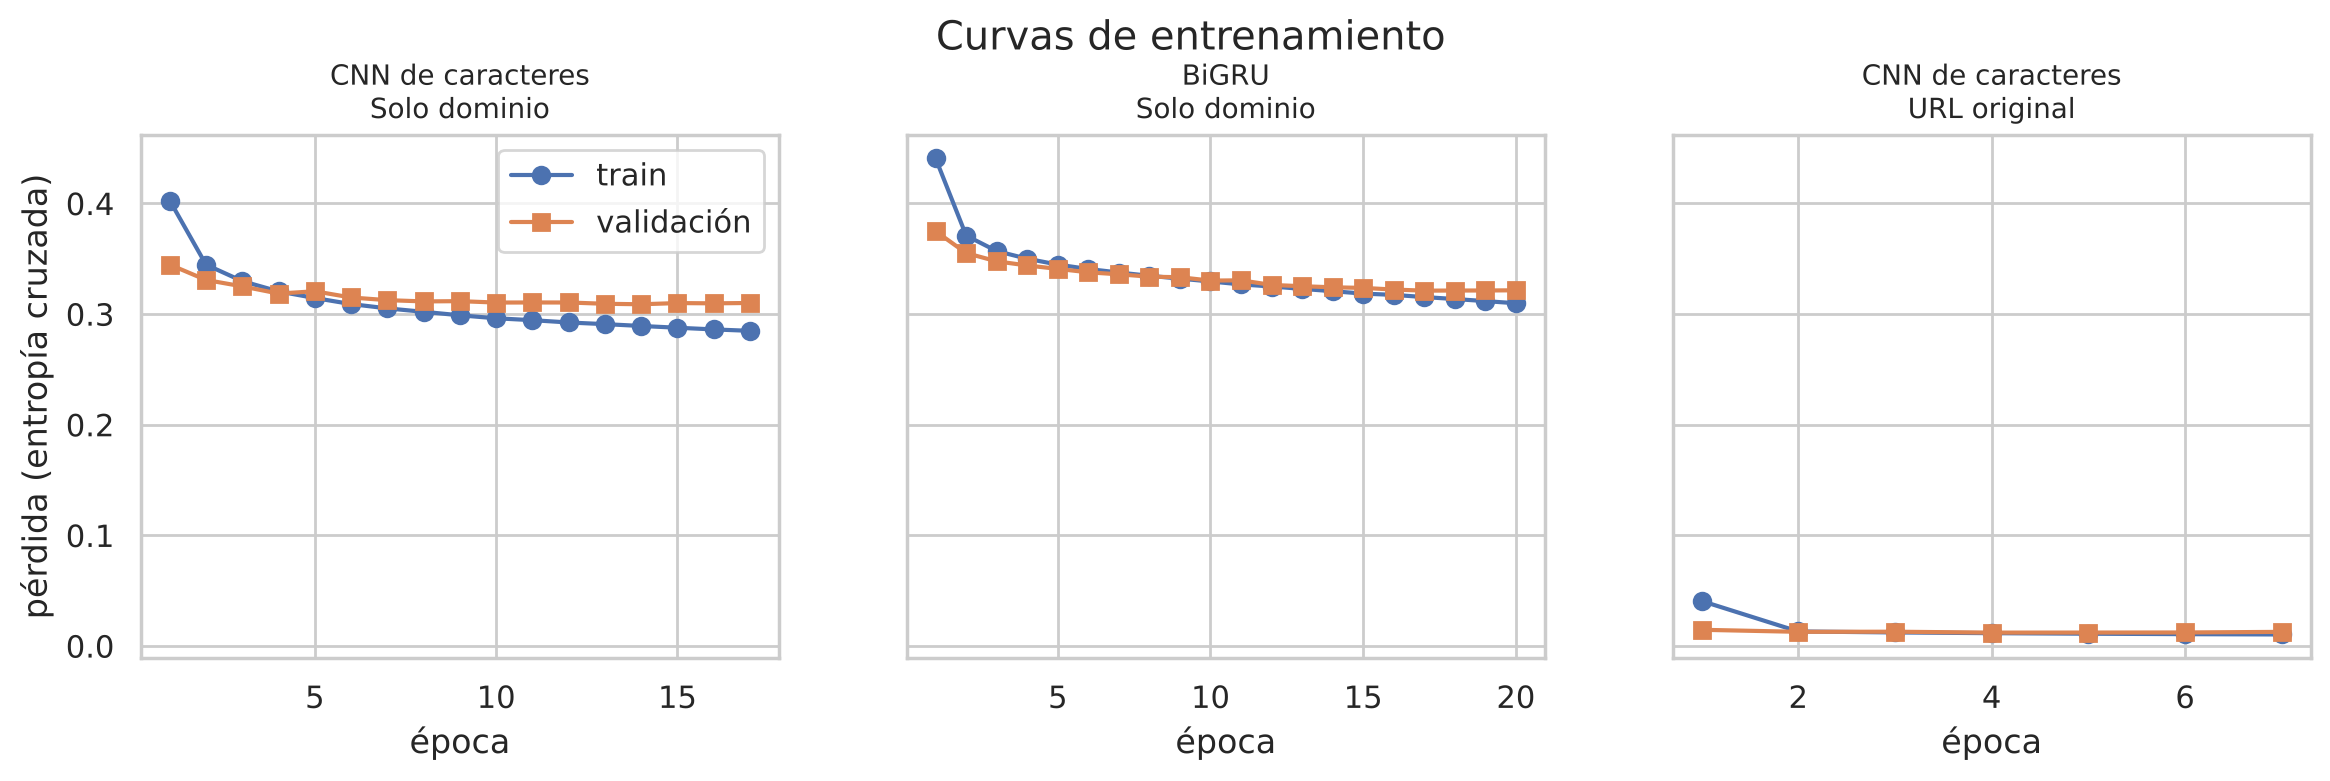

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), sharey=True)
for ax, ((nom, entrada), h) in zip(axes, historias.items()):
    ep = range(1, len(h["loss"]) + 1)
    ax.plot(ep, h["loss"], "o-", label="train"); ax.plot(ep, h["val_loss"], "s-", label="validación")
    ax.set_title(f"{nom}\n{entrada}", fontsize=10); ax.set_xlabel("época")
axes[0].set_ylabel("pérdida (entropía cruzada)"); axes[0].legend()
fig.suptitle("Curvas de entrenamiento", y=1.05); guardar(fig, "10_curvas_entrenamiento"); plt.show()

Si la pérdida de validación deja de bajar mientras la de train sigue bajando, el modelo empieza a **sobreajustar** (memorizar train). El *early stopping* corta justo ahí.

## 4. Comparación en validación

In [8]:
res_texto = pd.DataFrame(filas)
res_texto.to_csv(DIR_RES / "val_texto.csv", index=False)
cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "segundos_entrenamiento"]
display(res_texto.set_index(["entrada", "modelo"])[cols].style.format("{:.4f}", subset=cols[:-1])
        .background_gradient(subset=["f1"], cmap="Blues"))

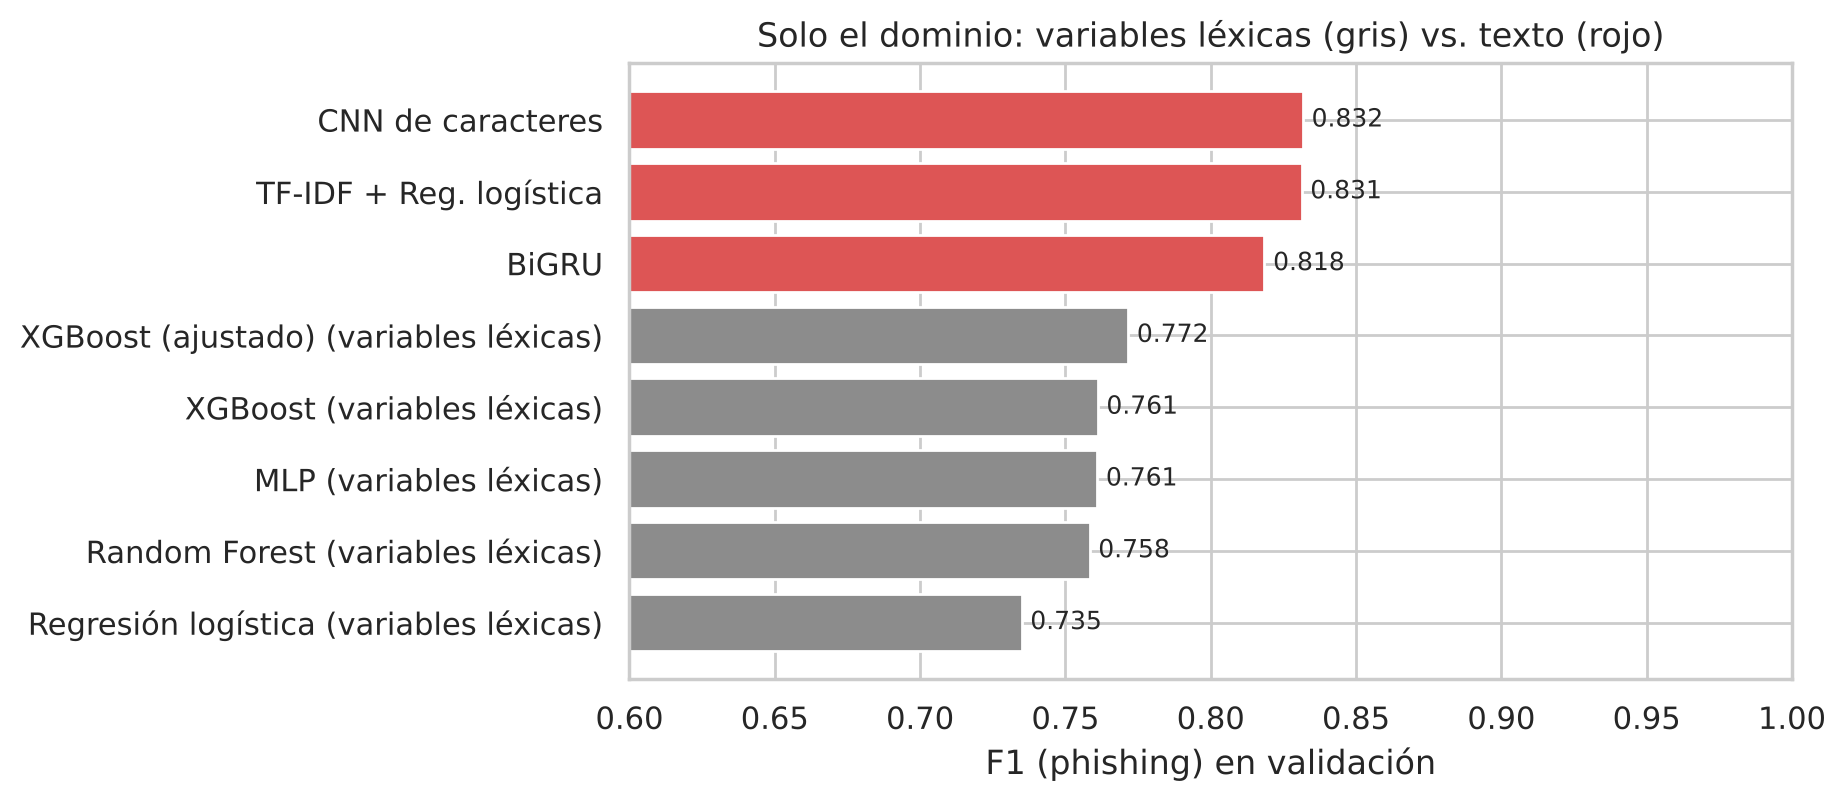

In [9]:
# Comparación justa: todos los modelos que solo miran el dominio (sin atajos)
tab = pd.read_csv(DIR_RES / "val_tabulares.csv").query("escenario == 'A4 · Léxicas del dominio'")
tab = tab.assign(modelo=tab.modelo + " (variables léxicas)")
dom = res_texto.query("entrada == 'Solo dominio'")
justa = pd.concat([tab[["modelo", "precision", "recall", "f1", "roc_auc"]],
                   dom[["modelo", "precision", "recall", "f1", "roc_auc"]]]).sort_values("f1")

fig, ax = plt.subplots(figsize=(7.5, 4))
colores = ["#DD5555" if "variables" not in m else "#8C8C8C" for m in justa.modelo]
ax.barh(justa.modelo, justa.f1, color=colores)
for i, v in enumerate(justa.f1):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0.6, 1.0); ax.set_xlabel("F1 (phishing) en validación")
ax.set_title("Solo el dominio: variables léxicas (gris) vs. texto (rojo)")
guardar(fig, "11_comparacion_dominio_val"); plt.show()

## 5. Guardado de las redes y sus codificadores

In [10]:
for (nom, entrada), red in redes.items():
    base = ("cnn" if nom.startswith("CNN") else "bigru") + ("_dominio" if entrada == "Solo dominio" else "_url_original")
    red.save(DIR_MOD / f"{base}.keras")
    print(f"models/{base}.keras  ({(DIR_MOD / f'{base}.keras').stat().st_size / 1e6:.1f} MB)")
codificadores["Solo dominio"].guardar(DIR_MOD / "codificador_dominio.json")
codificadores["URL original"].guardar(DIR_MOD / "codificador_url_original.json")

models/cnn_dominio.keras  (0.6 MB)
models/bigru_dominio.keras  (0.2 MB)
models/cnn_url_original.keras  (0.6 MB)


## 6. Conclusiones de este notebook

1. Con la **URL original**, tanto TF-IDF como la CNN llegan a F1 ≈ 0,997: aprenden el atajo del prefijo `https://www.` y la ausencia de ruta.
2. Con **solo el dominio**, la CNN de caracteres (F1 ≈ 0,832) y TF-IDF + regresión logística (F1 ≈ 0,831) quedan prácticamente empatados, y ambos superan claramente al mejor modelo con variables léxicas hechas a mano (XGBoost A4, F1 ≈ 0,772). Aprender directamente de los caracteres aporta unos 6 puntos de F1.
3. La CNN es más **precisa** (≈ 0,95 contra ≈ 0,91: menos falsas alarmas) pero detecta un poco menos (recall ≈ 0,74 contra ≈ 0,77). La BiGRU queda algo por debajo (F1 ≈ 0,818) y tarda más del doble en entrenarse en CPU.
4. Que una red neuronal no supere con claridad a una línea base bien construida es un resultado válido: con textos cortos como un dominio, los n-gramas de caracteres ya capturan casi toda la información.
5. Los n-gramas más asociados a phishing tienen sentido: TLDs que se ofrecían gratis o son muy baratos (`.cf`, `.ga`, `.ml`, `.top`) y fragmentos de servicios de alojamiento; los asociados a legítimas son `.gov`, `.edu`, `.mil` y TLDs de países. Esto da confianza en que el modelo de dominio aprende señales reales.